In [1]:
import torchvision.datasets as datasets
import torchvision.transforms as transforms
import torch
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
])

# Download and load the EuroSAT dataset (RGB version)
dataset = datasets.EuroSAT(
    root="../data/raw/EuroSAT",
    transform=transform,
    download=True,
)

In [3]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [4]:
generator = torch.Generator().manual_seed(0)
train_set, val_set, test_set = torch.utils.data.random_split(
    dataset, [.8, .1, .1], generator = generator)


In [5]:
# create data loader for training data
stats_dataloader = DataLoader(train_set, batch_size = 512, shuffle = False)

We want to transform the data by normalising it. To this end, we first compute its mean and standard deviation

In [6]:
s = torch.zeros(3, dtype=torch.float64)
s2 = torch.zeros(3, dtype=torch.float64)
N = 0
for batch, label in stats_dataloader:
    batch = batch.double()
    s += batch.sum(dim = (0, 2, 3))    # batch has shape [512, 3, 64, 64] : [images, channels, height, width]
    s2 += (batch ** 2).sum(dim = (0, 2, 3))
    N += batch.shape[0] * batch.shape[2] * batch.shape[3]

mean = s / N
stdv = (s2 / N - mean ** 2) ** .5

print("mean:", mean)
print("stdv:", stdv)

mean: tensor([0.3433, 0.3797, 0.4075], dtype=torch.float64)
stdv: tensor([0.2017, 0.1364, 0.1152], dtype=torch.float64)


Define the normalisation transform for the dataset. This will not change the images themselves, but rather transform them whenever they are requested from the dataset.

In [7]:
dataset.transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean.tolist(), stdv.tolist())
])

In [8]:
train_dataloader = DataLoader(train_set, batch_size = 64, shuffle = True)
val_dataloader = DataLoader(val_set, batch_size = 64, shuffle = False)
test_dataloader = DataLoader(test_set, batch_size = 64, shuffle = False)

Plot some images from the training set

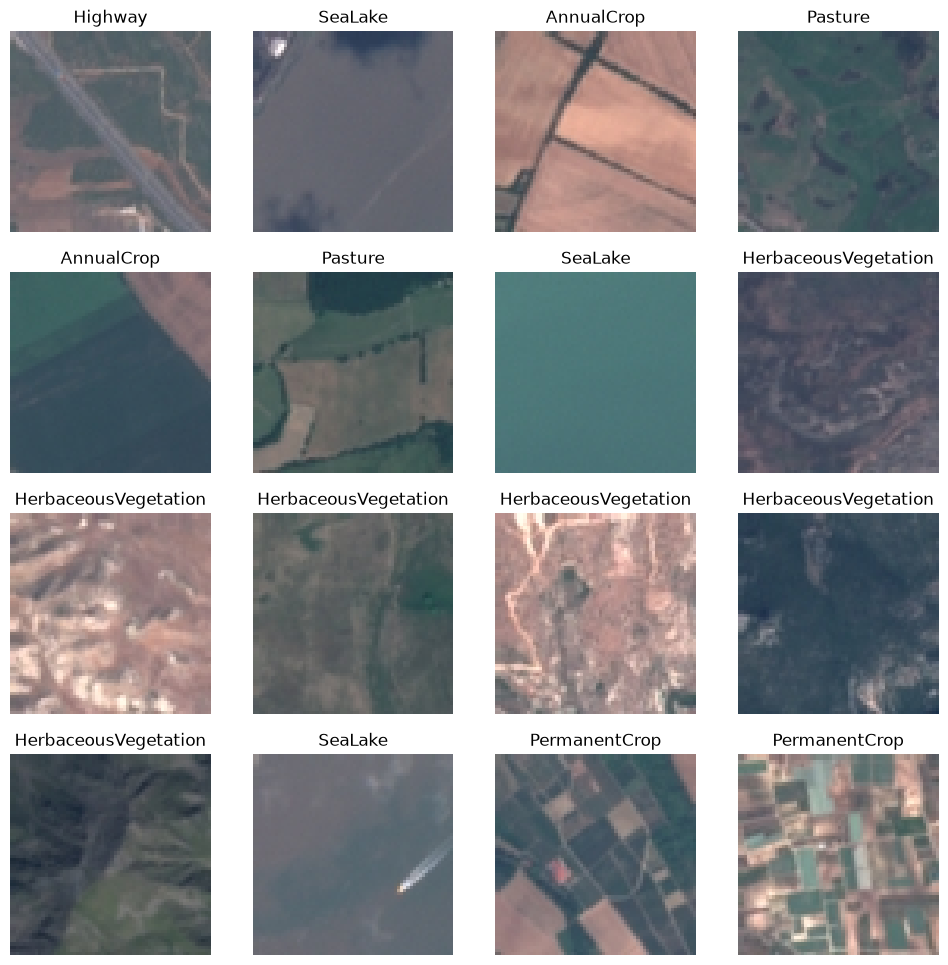

In [9]:
mean_t = mean.float().view(3, 1, 1)
std_t  = stdv.float().view(3, 1, 1)


figure = plt.figure(figsize=(12, 12))
cols, rows = 4, 4
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(train_set), size=(1,)).item()
    img, label = train_set[sample_idx]
    img = (img * std_t + mean_t).clamp(0, 1)
    figure.add_subplot(rows, cols, i)
    plt.title(dataset.classes[label])
    plt.axis("off")
    plt.imshow(img.permute(1, 2, 0))  # torch and matplotlib have different channel orders

plt.show()